<a href="https://colab.research.google.com/github/Sutrishna11/face_mesh/blob/main/iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Please upload your Iris.csv file


Saving Iris[1].csv to Iris[1].csv

First five rows of the dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset shape: (150, 6)

Species count:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Data standardized successfully!

Cluster Centers:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0      -0.050220     -0.880292       0.347532      0.282063
1      -1.014579      0.842307      -1.304878     -1.255129
2       1.135970      0.096598       0.996271      1.017172

Number of flowers in each cluster:
Clu

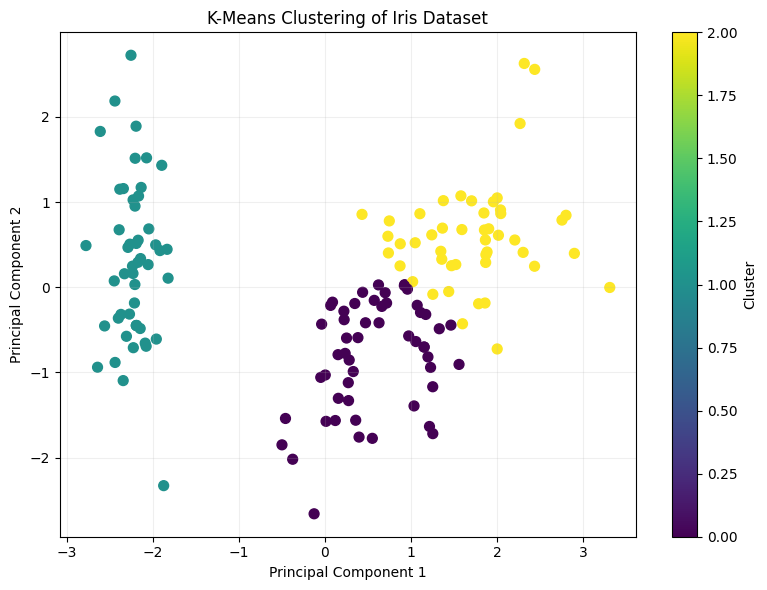

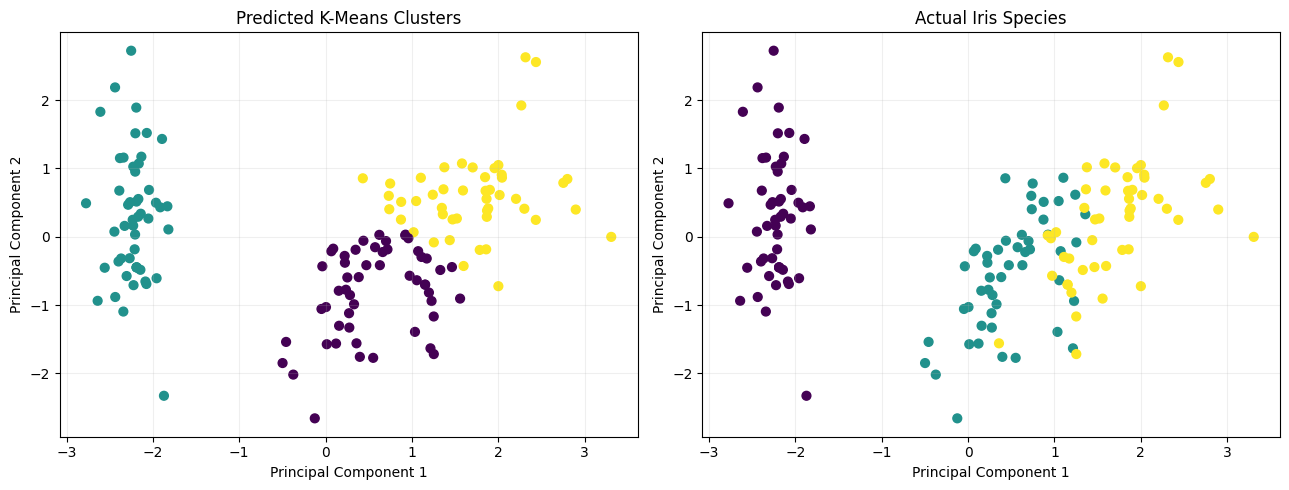


Adjusted Rand Index: 0.62

Actual Species vs Predicted Cluster:
       Species  Cluster
0  Iris-setosa        1
1  Iris-setosa        1
2  Iris-setosa        1
3  Iris-setosa        1
4  Iris-setosa        1
5  Iris-setosa        1
6  Iris-setosa        1
7  Iris-setosa        1
8  Iris-setosa        1
9  Iris-setosa        1

========== CONCLUSION ==========
K-Means grouped the Iris flowers into 3 clusters.
PCA reduced the four features to two components.
The explained variance ratio shows how much
information is retained by the two components.
The Adjusted Rand Index measures the agreement
between the clusters and actual species labels.


In [7]:

# =====================================================
# WEEK 3 ASSIGNMENT
# K-Means Clustering and PCA using Iris Dataset
# Google Colab
# =====================================================

# 1. Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

# 2. Upload the Iris.csv dataset
print("Please upload your Iris.csv file")
uploaded = files.upload()

# Automatically get the uploaded CSV filename
filename = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None
)

if filename is None:
    raise ValueError("Please upload a CSV file.")

# 3. Load the dataset
df = pd.read_csv(filename)

print("\nFirst five rows of the dataset:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nSpecies count:")
print(df["Species"].value_counts())

# 4. Select the four numerical features
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = df[features]
y = df["Species"]

# Check for missing values
if X.isnull().any().any():
    X = X.fillna(X.mean())

# 5. Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nData standardized successfully!")

# 6. Apply K-Means clustering with k=3
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nCluster Centers:")
print(pd.DataFrame(
    kmeans.cluster_centers_,
    columns=features
))

print("\nNumber of flowers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

# 7. Apply PCA to reduce dimensions to 2
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(round(pca.explained_variance_ratio_.sum(), 4))

# 8. Visualize K-Means clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clustering of Iris Dataset")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 9. Compare predicted clusters with actual species
species_codes, species_names = pd.factorize(y)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Predicted clusters
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

axes[0].set_title("Predicted K-Means Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid(alpha=0.2)

# Actual species
scatter = axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=species_codes,
    cmap="viridis",
    s=40
)

axes[1].set_title("Actual Iris Species")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 10. Compare clusters with actual species labels
score = adjusted_rand_score(y, df["Cluster"])

print("\nAdjusted Rand Index:", round(score, 3))

# 11. Display a sample of actual labels and predicted clusters
print("\nActual Species vs Predicted Cluster:")
print(df[["Species", "Cluster"]].head(10))

# 12. Conclusion
print("\n========== CONCLUSION ==========")
print("K-Means grouped the Iris flowers into 3 clusters.")
print("PCA reduced the four features to two components.")
print("The explained variance ratio shows how much")
print("information is retained by the two components.")
print("The Adjusted Rand Index measures the agreement")
print("between the clusters and actual species labels.")
